In [1]:
#Upload dataset ZIP
from google.colab import files
uploaded = files.upload()

Saving archive (4).zip to archive (4) (1).zip


In [2]:
#Extract dataset
import zipfile
import os
zip_file = next(iter(uploaded.keys()))
with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall("/content/fake_news_data")
print("Dataset extracted successfully!")

Dataset extracted successfully!


In [3]:
#Locate CSV files
import glob

csv_files = glob.glob(
    "/content/fake_news_data/**/*.csv",
    recursive=True
)
print("CSV files found:")
for file in csv_files:
    print(file)

CSV files found:
/content/fake_news_data/Fake.csv
/content/fake_news_data/True.csv


In [4]:
#Inspect the dataset
#Load both the CSV file
import pandas as pd
import os

fake_path = next(
    f for f in csv_files
    if os.path.basename(f).lower() == "fake.csv"
)

real_path = next(
    f for f in csv_files
    if os.path.basename(f).lower() == "true.csv"
)

fake_df = pd.read_csv(fake_path)
real_df = pd.read_csv(real_path)

print("Fake news shape:", fake_df.shape)
print("Real news shape:", real_df.shape)

print("\nFake columns:")
print(fake_df.columns.tolist())

print("\nReal columns:")
print(real_df.columns.tolist())

Fake news shape: (23481, 4)
Real news shape: (21417, 4)

Fake columns:
['title', 'text', 'subject', 'date']

Real columns:
['title', 'text', 'subject', 'date']


In [5]:
#Inspect records
print("FAKE NEWS EXAMPLES")
display(fake_df.head(3))

print("REAL NEWS EXAMPLES")
display(real_df.head(3))

FAKE NEWS EXAMPLES


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"


REAL NEWS EXAMPLES


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"


In [6]:
#Missing values
print("Fake missing values:")
print(fake_df.isnull().sum())

print("\nReal missing values:")
print(real_df.isnull().sum())

Fake missing values:
title      0
text       0
subject    0
date       0
dtype: int64

Real missing values:
title      0
text       0
subject    0
date       0
dtype: int64


In [7]:
#Duplicate values
print("Fake duplicate rows:", fake_df.duplicated().sum())
print("Real duplicate rows:", real_df.duplicated().sum())

Fake duplicate rows: 3
Real duplicate rows: 206


In [8]:
#Label distribution
print("Fake news count:", len(fake_df))
print("Real news count:", len(real_df))

Fake news count: 23481
Real news count: 21417


In [9]:
#Understand the input and target
#Combine files and assign labels
fake_df["label"] = 0
real_df["label"] = 1

df = pd.concat([fake_df, real_df], ignore_index=True)

df["news_text"] = (
    df["title"].fillna("").astype(str)
    + " "
    + df["text"].fillna("").astype(str)
)

df = df[["news_text", "label"]]

print(df.head())
print("\nDataset shape:", df.shape)
print("\nLabels:")
print(df["label"].value_counts())

                                           news_text  label
0   Donald Trump Sends Out Embarrassing New Year’...      0
1   Drunk Bragging Trump Staffer Started Russian ...      0
2   Sheriff David Clarke Becomes An Internet Joke...      0
3   Trump Is So Obsessed He Even Has Obama’s Name...      0
4   Pope Francis Just Called Out Donald Trump Dur...      0

Dataset shape: (44898, 2)

Labels:
label
0    23481
1    21417
Name: count, dtype: int64


In [10]:
#Data preprocessing
#Clean the dataset
import re

# Remove records with empty article text
df = df.dropna(subset=["news_text"])

# Remove extra spaces and line breaks
df["news_text"] = df["news_text"].apply(
    lambda x: re.sub(r"\s+", " ", str(x)).strip()
)

# Remove empty text after cleaning
df = df[df["news_text"] != ""]

# Remove exact duplicate article texts
df = df.drop_duplicates(subset=["news_text"])

# Reset index
df = df.reset_index(drop=True)

print("Dataset after cleaning:", df.shape)
print("\nLabel distribution:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Dataset after cleaning: (39100, 2)

Label distribution:
label
1    21195
0    17905
Name: count, dtype: int64

Missing values:
news_text    0
label        0
dtype: int64


In [30]:
#Train/test split
#Split data

from sklearn.model_selection import train_test_split

# Features and labels
X = df["news_text"]
y = df["label"]

# First split: 80% training, 20% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: divide remaining 20% into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 31280
Validation samples: 3910
Testing samples: 3910


In [31]:
train_dataset = NewsDataset(
    X_train,
    y_train,
    tokenizer,
    max_length=256
)

val_dataset = NewsDataset(
    X_val,
    y_val,
    tokenizer,
    max_length=256
)

test_dataset = NewsDataset(
    X_test,
    y_test,
    tokenizer,
    max_length=256
)

print("All datasets created successfully!")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

All datasets created successfully!
Train: 31280
Validation: 3910
Test: 3910


In [12]:
#BERT tokenizer(Bidirectional Encoder Representations from Transformers)
#Before BERT can understand a sentence, the sentence must be converted into a format the model can process.
#Load BERT tokenizer
!pip -q install transformers accelerate
print("Installation completed")

Installation completed


In [13]:
#Load tokenizer
from transformers import AutoTokenizer

MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully!")

Tokenizer loaded successfully!


In [14]:
#Understand input IDs, attention mask, padding and truncation

#Test tokenization
sample_text = X_train.iloc[0]
#Padding adds extra tokens to shorter inputs so they reach the required length.
encoded = tokenizer(
    sample_text,
    padding="max_length",
    truncation=True,
    max_length=256,
    return_tensors="pt"
)

print("Input IDs:")
#Tokens are converted into numerical IDs.
print(encoded["input_ids"][0][:20])

print("\nAttention Mask:")
#This tells BERT which tokens are actual content and which are padding.
print(encoded["attention_mask"][0][:20])

print("\nTokenized words:")
#News articles may be very long. Truncation limits them to the maximum sequence length we choose.
print(tokenizer.convert_ids_to_tokens(
    encoded["input_ids"][0][:20]
))

Input IDs:
tensor([ 101, 2182, 1521, 1055, 1996, 3537, 2933, 2000, 6033, 8398, 1010, 1998,
        2009, 1521, 1055, 3225, 2574, 1006, 2678, 1007])

Attention Mask:
tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

Tokenized words:
['[CLS]', 'here', '’', 's', 'the', 'democratic', 'plan', 'to', 'destroy', 'trump', ',', 'and', 'it', '’', 's', 'starting', 'soon', '(', 'video', ')']


In [15]:
#Prepare dataset for BERT
#Preparing our train and test data in a format that PyTorch and BERT can use.
#Create Dataset class
import torch
from torch.utils.data import Dataset

class NewsDataset(Dataset):

    def __init__(self, texts, labels, tokenizer, max_length=256):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):

        text = str(self.texts[index])
        label = int(self.labels[index])

        encoding = self.tokenizer(
            text,
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(label, dtype=torch.long)
        }

In [16]:
#Create train and test datasets
train_dataset = NewsDataset(
    X_train, y_train, tokenizer
)

test_dataset = NewsDataset(
    X_test, y_test, tokenizer
)

print("Training dataset created:", len(train_dataset))
print("Testing dataset created:", len(test_dataset))

Training dataset created: 31280
Testing dataset created: 7820


In [17]:
#Check and test with one record
sample = train_dataset[0]

print("Input IDs shape:", sample["input_ids"].shape)
print("Attention Mask shape:", sample["attention_mask"].shape)
print("Label:", sample["labels"])

Input IDs shape: torch.Size([256])
Attention Mask shape: torch.Size([256])
Label: tensor(0)


In [18]:
#Load BERT model
#Loading bert-base-uncased with a classification head for two classes.
#Because The pretrained BERT model needs an output layer suited to our classification task.
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={
        0: "FAKE",
        1: "REAL"
    },
    label2id={
        "FAKE": 0,
        "REAL": 1
    }
)

print("BERT classification model loaded!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT classification model loaded!


In [19]:
#Check GPU availability
#Checking whether Colab has given us a GPU.
#BERT fine-tuning is much faster on a GPU.

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
#Check GPU details
!nvidia-smi

Device: cuda
Wed Nov 18 05:23:42 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+----------------------------------

In [20]:
#Fine-tune BERT(A language model that understands context)
#Training the model
#Training configuration and Trainer
import torch
import transformers
import accelerate
import huggingface_hub

print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)
print("Accelerate version:", accelerate.__version__)
print("Hugging Face Hub version:", huggingface_hub.__version__)

print("\nGPU available:", torch.cuda.is_available())
print("Packages loaded successfully!")

PyTorch version: 2.14.1+cu130
Transformers version: 5.23.0
Accelerate version: 1.16.0
Hugging Face Hub version: 2.4.0

GPU available: True
Packages loaded successfully!


In [21]:
#Training configuration and Trainer
!pip install -U transformers accelerate

In [22]:
#Verify the imports again
import torch
import transformers
import accelerate
import numpy as np

from transformers import Trainer, TrainingArguments, DataCollatorWithPadding
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

print("All imports successful!")
print("--------------------")
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)
print("GPU available:", torch.cuda.is_available())

All imports successful!
--------------------
PyTorch: 2.14.1+cu130
Transformers: 5.23.0
Accelerate: 1.16.0
GPU available: True


In [23]:

from transformers import (
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import numpy as np

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=1)

    accuracy = accuracy_score(labels, predictions)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [26]:
#Training arguments
training_args = TrainingArguments(
    output_dir="/content/bert_fake_news_results",

    num_train_epochs=2,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    gradient_accumulation_steps=2,

    learning_rate=2e-5,
    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    logging_steps=100,

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    fp16=torch.cuda.is_available(),

    report_to="none",

    save_total_limit=2,

    seed=42
)

print("Training configuration ready!")

Training configuration ready!


In [32]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Trainer created successfully!")

Trainer created successfully!


In [33]:
from transformers import Trainer, DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Trainer created successfully!")

Trainer created successfully!


In [34]:
#Start training
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.000066,0.004306,0.999233,0.999234,0.999233,0.999233
2,0.000027,0.000212,0.999744,0.999744,0.999744,0.999744


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

In [35]:
#Get evaluation metrics
evaluation_results = trainer.evaluate()

print("\nEvaluation Results:")

for key, value in evaluation_results.items():
    if isinstance(value, (int, float)):
        print(f"{key}: {value:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.000027,0.000212,2,0.999744,0.999744,0.999744,0.999744



Evaluation Results:
eval_loss: 0.0002
eval_accuracy: 0.9997
eval_precision: 0.9997
eval_recall: 0.9997
eval_f1: 0.9997


              precision    recall  f1-score   support

        FAKE     1.0000    1.0000    1.0000      1791
        REAL     1.0000    1.0000    1.0000      2119

    accuracy                         1.0000      3910
   macro avg     1.0000    1.0000    1.0000      3910
weighted avg     1.0000    1.0000    1.0000      3910



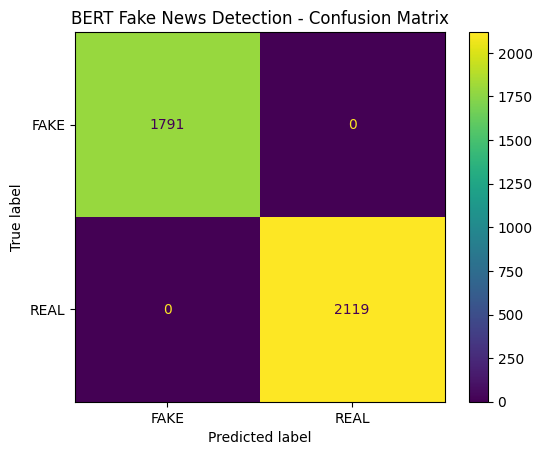

In [36]:
#Confusion matrix and classification report
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

pred_output = trainer.predict(test_dataset)

predictions = np.argmax(
    pred_output.predictions,
    axis=1
)

actual_labels = np.array(y_test)

print(classification_report(
    actual_labels,
    predictions,
    target_names=["FAKE", "REAL"],
    digits=4
))

cm = confusion_matrix(
    actual_labels,
    predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["FAKE", "REAL"]
)

disp.plot()
plt.title("BERT Fake News Detection - Confusion Matrix")
plt.show()

In [37]:
#Predict unseen news articles
#Create prediction function
def predict_news(news_text):

    model.eval()

    inputs = tokenizer(
        news_text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=256
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = model(**inputs)

        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        )

        predicted_class = torch.argmax(
            probabilities,
            dim=1
        ).item()

    label = "REAL" if predicted_class == 1 else "FAKE"

    confidence = probabilities[0][predicted_class].item()

    return {
        "prediction": label,
        "confidence": round(confidence * 100, 2)
    }


In [56]:
#Test new articles
##NASA's Perseverance Rover Explores Mars
#James Webb Space Telescope Studies the Early Universe
#Illinois governor enlists counterparts to attack Democrats in election ad CHICAGO (Reuters) - Illinois’ Republican governor has launched an unusual attack ad in his re-election campaign that features three neighboring governors crediting their states’ job gains to Illinois taxes crafted by a state House Democratic leader. Illinois Republican Governor Bruce Rauner, who kicked off his 2018 re-election campaign this week, saw his first term marred by a political impasse that left Illinois without a budget for two years before lawmakers overrode his veto this summer to raise taxes. Governors in the new ad include Missouri’s Eric Greitens, Wisconsin’s Scott Walker and Indiana’s Eric Holcomb - all Republicans like Rauner - thanking Rauner’s political foil, Illinois House Speaker Michael Madigan, for blocking reforms, raising taxes and sending jobs to their states. “Hoosiers love you, Mike Madigan,” Holcomb said in the ad. Among the Democrats whom Rauner, a wealthy businessman, could face aft
#God Created Our Hands? These Scientists Said He Did We all know that there is no way to be a scientist and a creationist at the same time. Science deals in facts, creationism deals in fantasy. So when the peer-reviewed, scientific journal PLOS ONE recently published a paper that claimed God designed our hands, the backlash was swift and loud.The paper was written by a team of scientists from China and Worcester, Massachusetts in order to better understand hand coordination. The abstract states, It is not understood which biomechanical characteristics are responsible for hand coordination and what specific effect each biomechanical characteristic has. But the abstract also contained something that made PLOS readers (and, at least, one editor) so angry the journal eventually retracted the paper, it said:The explicit functional link indicates that the biomechanical characteristic of tendinous connective architecture between muscles and articulations is the proper design by the Creator to

news = """
NASA's Perseverance rover landed on Mars in February 2021
and is studying the planet's geology while collecting rock samples.
"""

result = predict_news(news)

print("News:", news)
print("Prediction:", result["prediction"])
print("Confidence:", result["confidence"], "%")

News: 
NASA's Perseverance rover landed on Mars in February 2021
and is studying the planet's geology while collecting rock samples.

Prediction: FAKE
Confidence: 99.74 %


In [46]:
print("Dataset label counts:")
print(df["label"].value_counts())

print("\nLabel names:")
print(model.config.id2label)

print("\nLabel mapping:")
print(model.config.label2id)

Dataset label counts:
label
1    21195
0    17905
Name: count, dtype: int64

Label names:
{0: 'FAKE', 1: 'REAL'}

Label mapping:
{'FAKE': 0, 'REAL': 1}


In [47]:
import torch
import pandas as pd

def debug_bert_prediction(text):
    model.eval()
    model.to(device)

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=256
    )

    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=1)[0]

    return {
        "FAKE probability": round(probabilities[0].item() * 100, 2),
        "REAL probability": round(probabilities[1].item() * 100, 2)
    }

sample_real = """
NASA's Perseverance rover landed on Mars in February 2021
and is studying the planet's geology while collecting rock samples.
"""

sample_fake = """
Scientists have invented a machine that can stop every cyclone
using sound waves. The device will be installed worldwide next month.
"""

print("REAL-style sample:")
print(debug_bert_prediction(sample_real))

print("\nFAKE-style sample:")
print(debug_bert_prediction(sample_fake))

REAL-style sample:
{'FAKE probability': 99.74, 'REAL probability': 0.26}

FAKE-style sample:
{'FAKE probability': 99.87, 'REAL probability': 0.13}


In [48]:
print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

print("\nLast training logs:")
print(trainer.state.log_history[-10:])

Training dataset: 31280
Validation dataset: 3910
Testing dataset: 3910

Last training logs:
[{'loss': 3.62241268157959e-05, 'grad_norm': 0.0009779400425031781, 'learning_rate': 3.1253196930946294e-06, 'epoch': 1.6879795396419437, 'step': 3300}, {'loss': 0.006827079653739929, 'grad_norm': 0.0007174277561716735, 'learning_rate': 2.61381074168798e-06, 'epoch': 1.7391304347826086, 'step': 3400}, {'loss': 2.878740429878235e-05, 'grad_norm': 0.0012747574364766479, 'learning_rate': 2.10230179028133e-06, 'epoch': 1.7902813299232738, 'step': 3500}, {'loss': 4.298493266105652e-05, 'grad_norm': 0.0007306698826141655, 'learning_rate': 1.5907928388746805e-06, 'epoch': 1.8414322250639388, 'step': 3600}, {'loss': 2.8498172760009766e-05, 'grad_norm': 0.0009558387100696564, 'learning_rate': 1.0792838874680307e-06, 'epoch': 1.8925831202046037, 'step': 3700}, {'loss': 4.0854066610336305e-05, 'grad_norm': 0.0006728674052283168, 'learning_rate': 5.677749360613811e-07, 'epoch': 1.9437340153452687, 'step': 3

In [50]:
#Test BERT on its original unseen test dataset
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np

# Evaluate on the held-out test dataset
test_output = trainer.predict(test_dataset)

# Convert logits into predicted classes
test_predictions = np.argmax(test_output.predictions, axis=1)

# Actual labels
test_actual = np.array(y_test)

print("Test Accuracy:", accuracy_score(test_actual, test_predictions))

print("\nClassification Report:")
print(classification_report(
    test_actual,
    test_predictions,
    target_names=["FAKE", "REAL"],
    digits=4
))

print("\nConfusion Matrix:")
print(confusion_matrix(test_actual, test_predictions))

Test Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

        FAKE     1.0000    1.0000    1.0000      1791
        REAL     1.0000    1.0000    1.0000      2119

    accuracy                         1.0000      3910
   macro avg     1.0000    1.0000    1.0000      3910
weighted avg     1.0000    1.0000    1.0000      3910


Confusion Matrix:
[[1791    0]
 [   0 2119]]


In [51]:
#Check actual test articles and their predictions
import pandas as pd

results_df = pd.DataFrame({
    "Actual": test_actual,
    "Predicted": test_predictions
})

results_df["Actual"] = results_df["Actual"].map({0: "FAKE", 1: "REAL"})
results_df["Predicted"] = results_df["Predicted"].map({0: "FAKE", 1: "REAL"})

# Add the article text
results_df["News"] = list(X_test)

# Randomly display 10 test examples
display(results_df.sample(10, random_state=42))

,Actual,Predicted,News
2793,REAL,REAL,CIA contractors likely source of latest WikiLe...
2803,FAKE,FAKE,(VIDEO)INCREDIBLE ACCOUNT FROM SHERIFF MICHAEL...
2218,FAKE,FAKE,ADMIRAL JAMES “ACE” LYONS WARNS: What The Join...
3111,REAL,REAL,Trump blasts PGA Tour for plan to move golf to...
3161,REAL,REAL,Infrastructure would be popular bipartisan ste...
3182,REAL,REAL,Kremlin accuses West of 'whipping up hysteria'...
166,FAKE,FAKE,Joy Behar Delivers BRUTALLY Honest Message To ...
1731,REAL,REAL,Russia's U.N. envoy calls for 'cool heads' on ...
322,FAKE,FAKE,MUST WATCH AND SHARE VIDEO: BRIT HUME GIVES TH...
1034,FAKE,FAKE,Palin Stands With Disgraced ESPN Analyst Curt ...


In [61]:
# Select one real and one fake article from the original dataset
real_sample = df[df["label"] == 1].sample(1, random_state=42).iloc[0]
fake_sample = df[df["label"] == 0].sample(1, random_state=42).iloc[0]

print("REAL ARTICLE FROM DATASET")
print(real_sample["news_text"][:1000])
print("\nBERT probabilities:")
print(debug_bert_prediction(real_sample["news_text"]))

print("\n" + "=" * 80)

print("FAKE ARTICLE FROM DATASET")
print(fake_sample["news_text"][:1000])
print("\nBERT probabilities:")
print(debug_bert_prediction(fake_sample["news_text"]))

REAL ARTICLE FROM DATASET
Illinois governor enlists counterparts to attack Democrats in election ad CHICAGO (Reuters) - Illinois’ Republican governor has launched an unusual attack ad in his re-election campaign that features three neighboring governors crediting their states’ job gains to Illinois taxes crafted by a state House Democratic leader. Illinois Republican Governor Bruce Rauner, who kicked off his 2018 re-election campaign this week, saw his first term marred by a political impasse that left Illinois without a budget for two years before lawmakers overrode his veto this summer to raise taxes. Governors in the new ad include Missouri’s Eric Greitens, Wisconsin’s Scott Walker and Indiana’s Eric Holcomb - all Republicans like Rauner - thanking Rauner’s political foil, Illinois House Speaker Michael Madigan, for blocking reforms, raising taxes and sending jobs to their states. “Hoosiers love you, Mike Madigan,” Holcomb said in the ad. Among the Democrats whom Rauner, a wealthy b